# 01 - SST-2 dataset exploration and split preparation

Project: *Evolutionary Prompt Optimization for LLM-Based Sentiment Analysis (Genetic Algorithm)*.

This notebook explains the **SST-2** data (Stanford Sentiment Treebank, binary, GLUE version), builds the
reproducible **optimization / validation** splits and saves them for the rest of the team.

**Labels:** `0 = negative`, `1 = positive`.

**Test-set protection.** The final test set is the *official GLUE validation split* (872 labelled sentences).
This notebook **never loads, explores or saves it**. The only exception is one leakage check inside
`prepare_splits`, which compares texts in memory and reports *counts only*.
The official GLUE `test` split has hidden labels (`-1`), so it cannot be used for evaluation and is not used.

**Kaggle:** turn *Internet* ON (Settings, right sidebar) to download the data. No GPU is needed.

## 1. Environment

In [16]:
%pip install -q datasets pandas numpy scikit-learn matplotlib pytest

Note: you may need to restart the kernel to use updated packages.


In [ ]:

import sys
from pathlib import Path

# Find the project root (the folder containing src/data/sst2_data.py)
try:
    ROOT = next(
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "src" / "data" / "sst2_data.py").exists()
    )
except StopIteration:
    raise RuntimeError(
        "Project root not found: make sure the notebook is run "
        "from inside the project folder."
    )

# Add the project root to Python's import path
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Project root:", ROOT)


Project root: c:\Users\hp\Documents\3CS\S1\Advanced_AI\Project


In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data.sst2_data import LABEL_NAMES, check_splits, load_train, prepare_splits

(ROOT / "data").mkdir(exist_ok=True)
(ROOT / "results").mkdir(exist_ok=True)

## 2. Download the labelled training split

`load_train()` downloads **only** the `train` split (`nyu-mll/glue`, config `sst2`; fallback `stanfordnlp/sst2`).
Nothing is filtered or removed.

In [19]:
train = load_train()
print("source:", train.attrs.get("source"))
print("shape :", train.shape)
train.head(8)

source: nyu-mll/glue:sst2
shape : (67349, 2)


,text,label
0,hide new secretions from the parental units,0
1,"contains no wit , only labored gags",0
2,that loves its characters and communicates som...,1
3,remains utterly satisfied to remain the same t...,0
4,on the worst revenge-of-the-nerds clichés the ...,0
5,that 's far too tragic to merit such superfici...,0
6,demonstrates that the director of such hollywo...,1
7,of saucy,1


## 3. Structure

Two columns: `text` (a sentence or a phrase from a movie review, lower-cased and tokenized) and `label` (0 or 1).
Many training rows are short **phrases** of the original sentences (SST has phrase-level labels).

In [20]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 67349 entries, 0 to 67348
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    67349 non-null  str  
 1   label   67349 non-null  int64
dtypes: int64(1), str(1)
memory usage: 4.4 MB


## 4. Label distribution

,label,name,count,share
0,0,negative,29780,0.4422
1,1,positive,37569,0.5578


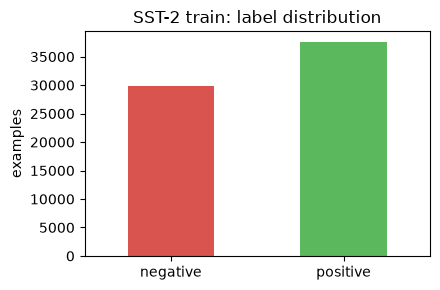

In [21]:
counts = train["label"].value_counts().sort_index()
dist = pd.DataFrame({"label": counts.index, "name": [LABEL_NAMES[i] for i in counts.index],
                     "count": counts.values, "share": (counts / len(train)).round(4).values})
display(dist)

ax = dist.plot.bar(x="name", y="count", legend=False, rot=0, figsize=(4.5, 3), color=["#d9534f", "#5cb85c"])
ax.set_title("SST-2 train: label distribution"); ax.set_xlabel(""); ax.set_ylabel("examples")
plt.tight_layout(); plt.show()

## 5. Missing values and duplicates

In [22]:
print("missing values per column:"); print(train.isna().sum().to_string())
print("empty texts:", int((train["text"].str.strip() == "").sum()))

norm = train["text"].str.lower().str.split().str.join(" ")          # only for comparison
dup_rows = int(norm.duplicated(keep=False).sum())
dup_texts = int(norm[norm.duplicated(keep=False)].nunique())
conflicting = int((train.assign(norm=norm).groupby("norm")["label"].nunique() > 1).sum())
print(f"rows whose text appears more than once : {dup_rows}")
print(f"distinct texts that are duplicated     : {dup_texts}")
print(f"duplicated texts with CONFLICTING labels: {conflicting}")

missing values per column:
text     0
label    0
empty texts: 0
rows whose text appears more than once : 742
distinct texts that are duplicated     : 371
duplicated texts with CONFLICTING labels: 5


Duplicates with consistent labels are kept. Texts with conflicting labels are removed during cleaning.

To prevent data leakage between optimization and validation, all rows sharing the same normalized text are assigned to the same split. Therefore, identical normalized texts cannot appear in both `opt` and `val`.

## 6. Sentence lengths (words per text)

,n_words
count,67349.00
mean,9.41
std,8.07
min,1.00
25%,3.00
50%,7.00
75%,13.00
max,52.00


share of short texts: {'<= 3 words': 0.2753, '<= 5 words': 0.4251, '<= 10 words': 0.6646}


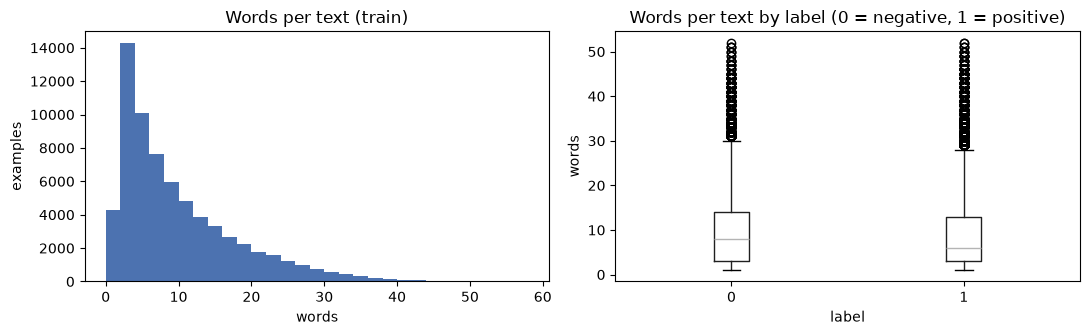

In [23]:
train["n_words"] = train["text"].str.split().str.len()
display(train["n_words"].describe().round(2).to_frame("n_words"))
short = {f"<= {k} words": round(float((train["n_words"] <= k).mean()), 4) for k in (3, 5, 10)}
print("share of short texts:", short)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(train["n_words"], bins=range(0, 60, 2), color="#4c72b0")
axes[0].set_title("Words per text (train)"); axes[0].set_xlabel("words"); axes[0].set_ylabel("examples")
train.boxplot(column="n_words", by="label", ax=axes[1], grid=False)
axes[1].set_title("Words per text by label (0 = negative, 1 = positive)"); axes[1].set_xlabel("label"); axes[1].set_ylabel("words")
plt.suptitle(""); plt.tight_layout(); plt.show()

**Remark for the methodology.** The final test set consists of full sentences, while a large part of the training
data are short phrases, so the *length distribution of train and test may differ*. We deliberately do **not**
look at the test set here; this possible shift is documented as a limitation in the README.

## 7. Example texts (train only)

In [24]:
for lab in (0, 1):
    print(f"--- {LABEL_NAMES[lab]} ---")
    for t in train.loc[train["label"] == lab, "text"].sample(5, random_state=0):
        print("-", t)

--- negative ---
- deny its seriousness and quality
- completely lacking in chills
- this sade is hardly a perverse , dangerous libertine and agitator -- which would have made for better drama .
- were dylan thomas alive to witness first-time director ethan hawke 's strained chelsea walls , he might have been tempted to change his landmark poem to , ` do not go gentle into that good theatre . '
- defined by childlike dimness and a handful of quirks
--- positive ---
- a timely look back at civil disobedience , anti-war movements and the power of strong voices .
- any less entertaining
- excellent performances
- besides its terrific performances , is fontaine 's willingness to wander into the dark areas of parent-child relationships without flinching .
- a fairly revealing study of its two main characters


## 8. Reproducible stratified split: 80 % optimization / 20 % validation

* `opt` (80 %): the GA computes fitness here.
* `val` (20 %): compare promising prompts and choose the final one.
* Stratified on the label, `random_state=42`. Every labelled training example goes to exactly one of the two.
* The checks (reproducibility, stratification, no row overlap, full coverage) run inside `prepare_splits`.
* Saved: `data/opt.csv`, `data/val.csv`, `data/split_info.json`. **The final test set is not saved.**

In [25]:
splits = prepare_splits(save_dir=ROOT / "data")     # seed=42, opt_fraction=0.8
print(json.dumps(splits.info, indent=2))

{
  "source": "nyu-mll/glue:sst2",
  "seed": 42,
  "selected_candidate_seed": 42,
  "split_selection_score": 7.308679846080949e-06,
  "opt_class_ratio_difference": 1.6415724910512353e-06,
  "val_class_ratio_difference": 6.5661680772599595e-06,
  "requested_opt_fraction": 0.8,
  "actual_opt_fraction": 0.799997,
  "actual_val_fraction": 0.200003,
  "label_encoding": {
    "0": "negative",
    "1": "positive"
  },
  "cleaning": {
    "n_original": 67349,
    "n_removed_conflicting_rows": 10,
    "n_conflicting_unique_texts": 5,
    "n_after_cleaning": 67339,
    "n_ordinary_duplicate_rows_kept": 366
  },
  "n_total": 67339,
  "n_total_after_cleaning": 67339,
  "opt": {
    "n": 53871,
    "n_negative": 23820,
    "n_positive": 30051,
    "positive_ratio": 0.557833
  },
  "val": {
    "n": 13468,
    "n_negative": 5955,
    "n_positive": 7513,
    "positive_ratio": 0.557841
  },
  "n_normalized_texts_shared_between_opt_and_val": 0,
  "checks": {
    "no_row_overlap_between_opt_and_val": tr

### Cleaning summary

The following information summarizes the cleaning operations
performed before creating the optimization and validation splits.

In [26]:
print("Cleaning information:")
print(json.dumps(splits.info, indent=2))

Cleaning information:
{
  "source": "nyu-mll/glue:sst2",
  "seed": 42,
  "selected_candidate_seed": 42,
  "split_selection_score": 7.308679846080949e-06,
  "opt_class_ratio_difference": 1.6415724910512353e-06,
  "val_class_ratio_difference": 6.5661680772599595e-06,
  "requested_opt_fraction": 0.8,
  "actual_opt_fraction": 0.799997,
  "actual_val_fraction": 0.200003,
  "label_encoding": {
    "0": "negative",
    "1": "positive"
  },
  "cleaning": {
    "n_original": 67349,
    "n_removed_conflicting_rows": 10,
    "n_conflicting_unique_texts": 5,
    "n_after_cleaning": 67339,
    "n_ordinary_duplicate_rows_kept": 366
  },
  "n_total": 67339,
  "n_total_after_cleaning": 67339,
  "opt": {
    "n": 53871,
    "n_negative": 23820,
    "n_positive": 30051,
    "positive_ratio": 0.557833
  },
  "val": {
    "n": 13468,
    "n_negative": 5955,
    "n_positive": 7513,
    "positive_ratio": 0.557841
  },
  "n_normalized_texts_shared_between_opt_and_val": 0,
  "checks": {
    "no_row_overlap_be

In [27]:
conflict_rows = (
    train.assign(norm=norm)
         .groupby("norm")
         .filter(lambda g: g["label"].nunique() > 1)
)

print("Conflicting rows:", len(conflict_rows))
print("Conflicting unique texts:", conflicting)
display(conflict_rows[["text", "label"]].head(20))

Conflicting rows: 10
Conflicting unique texts: 5


,text,label
1433,laughably,0
8493,the only reason,1
10928,excruciatingly,0
18521,sleeper,0
30663,excruciatingly,1
38655,sleeper,1
38764,sillier,0
42877,sillier,1
54844,laughably,1
66327,the only reason,0


In [28]:
print("re-running the checks:", check_splits(splits, train))

summary = pd.DataFrame({
    "split": ["opt", "val"],
    "n": [len(splits.opt), len(splits.val)],
    "positive_ratio": [splits.opt["label"].mean().round(4), splits.val["label"].mean().round(4)],
    "mean_words": [splits.opt["text"].str.split().str.len().mean().round(2),
                   splits.val["text"].str.split().str.len().mean().round(2)],
})
display(summary)

re-running the checks: {'no_row_overlap_between_opt_and_val': True, 'no_text_overlap_between_opt_and_val': True, 'labels_are_0_or_1': True, 'opt_is_reasonably_stratified': True, 'val_is_reasonably_stratified': True, 'opt_plus_val_cover_every_cleaned_train_row': True, 'reproducible_with_same_seed': True}


,split,n,positive_ratio,mean_words
0,opt,53871,0.5578,9.39
1,val,13468,0.5578,9.48


### Class distribution comparison

We compare the positive and negative class proportions in the
optimization and validation subsets to verify that both subsets
have similar class distributions.

,opt,val
Negative,0.442167,0.442159
Positive,0.557833,0.557841


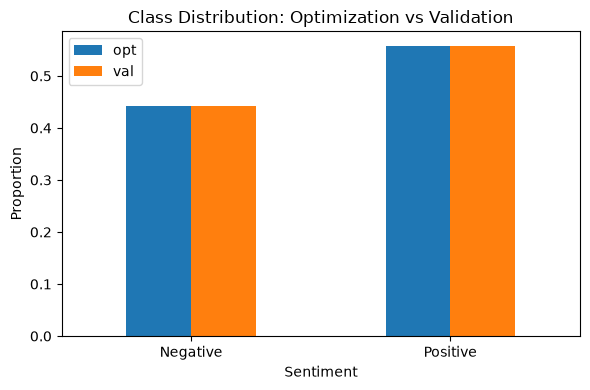

In [29]:
split_distribution = pd.DataFrame({
    "opt": splits.opt["label"].value_counts(normalize=True),
    "val": splits.val["label"].value_counts(normalize=True),
}).sort_index()

split_distribution.index = ["Negative", "Positive"]

display(split_distribution)

ax = split_distribution.plot(
    kind="bar",
    figsize=(6, 4),
    title="Class Distribution: Optimization vs Validation"
)

ax.set_ylabel("Proportion")
ax.set_xlabel("Sentiment")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Leakage checks
* opt and val are disjoint by row (`train_idx`) - checked above.
* `test_leakage_check` in `split_info.json` holds only **counts** of opt/val texts that also occur in the final test
  set. If these are not zero, nothing was removed automatically: discuss it with the team.

## 9. Save the exploration summary

In [30]:
exploration = {
    "source": train.attrs.get("source"),
    "n_train_rows": int(len(train)),
    "label_counts": {LABEL_NAMES[int(k)]: int(v) for k, v in counts.items()},
    "missing_values": {c: int(v) for c, v in train[["text", "label"]].isna().sum().items()},
    "duplicates": {"rows_in_duplicated_texts": dup_rows, "distinct_duplicated_texts": dup_texts,
                   "duplicated_texts_with_conflicting_labels": conflicting},
    "words_per_text": {k: round(float(v), 3) for k, v in train["n_words"].describe().items()},
    "split_info": splits.info,
}
(ROOT / "results" / "exploration_summary.json").write_text(json.dumps(exploration, indent=2), encoding="utf-8")
print(sorted(p.name for p in (ROOT / "data").iterdir()), sorted(p.name for p in (ROOT / "results").iterdir()))

['opt.csv', 'split_info.json', 'val.csv'] ['exploration_summary.json']
